###เชื่อม google drive

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
T1_IMAGE_DIR = "/content/drive/MyDrive/Image_Project/Dataset/T1/images"
T1_LABEL_DIR = "/content/drive/MyDrive/Image_Project/Dataset/T1/labels"

In [ ]:
import os

image_extensions = (".jpg", ".jpeg", ".png")

images = [
    f for f in os.listdir(T1_IMAGE_DIR)
    if f.lower().endswith(image_extensions)
]

labels = [
    f for f in os.listdir(T1_LABEL_DIR)
    if f.lower().endswith(".txt")
]

print("Number of images :", len(images))
print("Number of labels :", len(labels))

Number of images : 246
Number of labels : 246


**T2 - Sythethic Dark**

สร้างฟังก์ชันทำภาพมืด ตาม brief ใช้แนวคิด

$$ I_{dark}(x)=(gain \cdot I(x))^\gamma $$

โดย normalize ภาพให้อยู่ช่วง 0–1 ก่อน แล้วค่อยนำกลับเป็น 0–255

In [ ]:
import cv2
import numpy as np

def darken_image(img, gamma=2.0, gain=0.5):
    # 0-255 -> 0-1
    x = img.astype(np.float32) / 255.0

    # ลดความสว่างด้วย gain
    x = x * gain

    # Gamma degradation
    x = x ** gamma

    # กลับเป็น 0-255
    x = np.clip(x * 255.0, 0, 255)

    return x.astype(np.uint8)

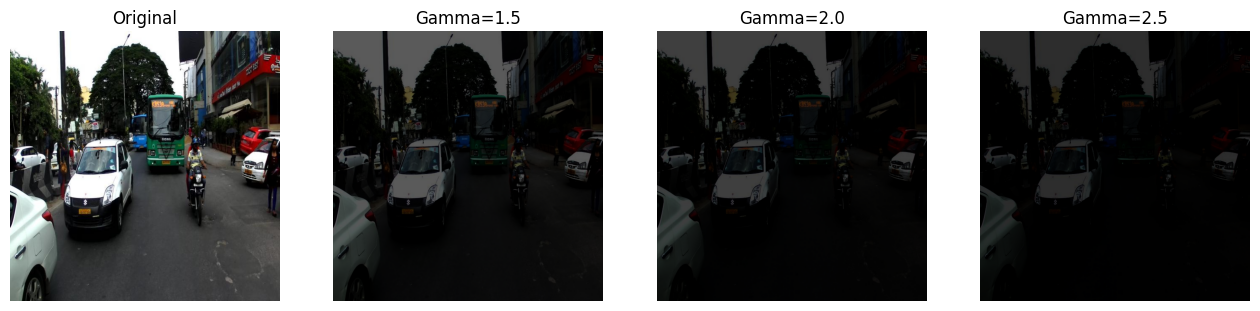

In [ ]:
import matplotlib.pyplot as plt

sample_path = os.path.join(T1_IMAGE_DIR, images[0])

img = cv2.imread(sample_path)

gamma_values = [1.5, 2.0, 2.5]
gain = 0.5 # ถ้ามืดไปให้ปรับ gain เพิ่ม

plt.figure(figsize=(16, 4))

# Original
plt.subplot(1, 4, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")

# Dark versions
for i, gamma in enumerate(gamma_values, start=2):
    dark = darken_image(img, gamma=gamma, gain=gain)

    plt.subplot(1, 4, i)
    plt.imshow(cv2.cvtColor(dark, cv2.COLOR_BGR2RGB))
    plt.title(f"Gamma={gamma}")
    plt.axis("off")

plt.show()

###สร้าง Folder T2 - gamma 1.5 , 2 , 2.5

In [ ]:
T2_ROOT = "/content/drive/MyDrive/Image_Project/Dataset/T2"

In [ ]:
gamma_values = [1.5, 2.0, 2.5]

for gamma in gamma_values:
    os.makedirs(f"{T2_ROOT}/gamma_{gamma}/images", exist_ok=True)
    os.makedirs(f"{T2_ROOT}/gamma_{gamma}/labels", exist_ok=True)

print("Folders created")

Folders created


In [ ]:
import shutil
from tqdm import tqdm

gamma_values = [1.5, 2.0, 2.5]
gain = 0.5

for gamma in gamma_values:
    output_img_dir = f"{T2_ROOT}/gamma_{gamma}/images"
    output_label_dir = f"{T2_ROOT}/gamma_{gamma}/labels"

    print(f"Generating gamma {gamma}")

    for filename in tqdm(images):
        input_path = os.path.join(T1_IMAGE_DIR, filename)

        img = cv2.imread(input_path)

        if img is None:
            print("Cannot read:", filename)
            continue

        dark_img = darken_image(
            img,
            gamma=gamma,
            gain=gain
        )

        # Save dark image
        output_path = os.path.join(output_img_dir, filename)
        cv2.imwrite(output_path, dark_img)

        # Copy original label
        base_name = os.path.splitext(filename)[0]
        label_name = base_name + ".txt"

        src_label = os.path.join(T1_LABEL_DIR, label_name)
        dst_label = os.path.join(output_label_dir, label_name)

        if os.path.exists(src_label):
            shutil.copy2(src_label, dst_label)

print("Finished!")

Generating gamma 1.5


100%|██████████| 246/246 [00:21<00:00, 11.23it/s]


Generating gamma 2.0


100%|██████████| 246/246 [00:14<00:00, 17.55it/s]


Generating gamma 2.5


100%|██████████| 246/246 [00:19<00:00, 12.43it/s]

Finished!


In [ ]:
for gamma in gamma_values:
    img_dir = f"{T2_ROOT}/gamma_{gamma}/images"
    label_dir = f"{T2_ROOT}/gamma_{gamma}/labels"

    img_count = len([
        f for f in os.listdir(img_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    label_count = len([
        f for f in os.listdir(label_dir)
        if f.endswith(".txt")
    ])

    print(
        f"Gamma {gamma}:",
        img_count, "images,",
        label_count, "labels"
    )

Gamma 1.5: 246 images, 246 labels
Gamma 2.0: 246 images, 246 labels
Gamma 2.5: 246 images, 246 labels


เช็คภาพ

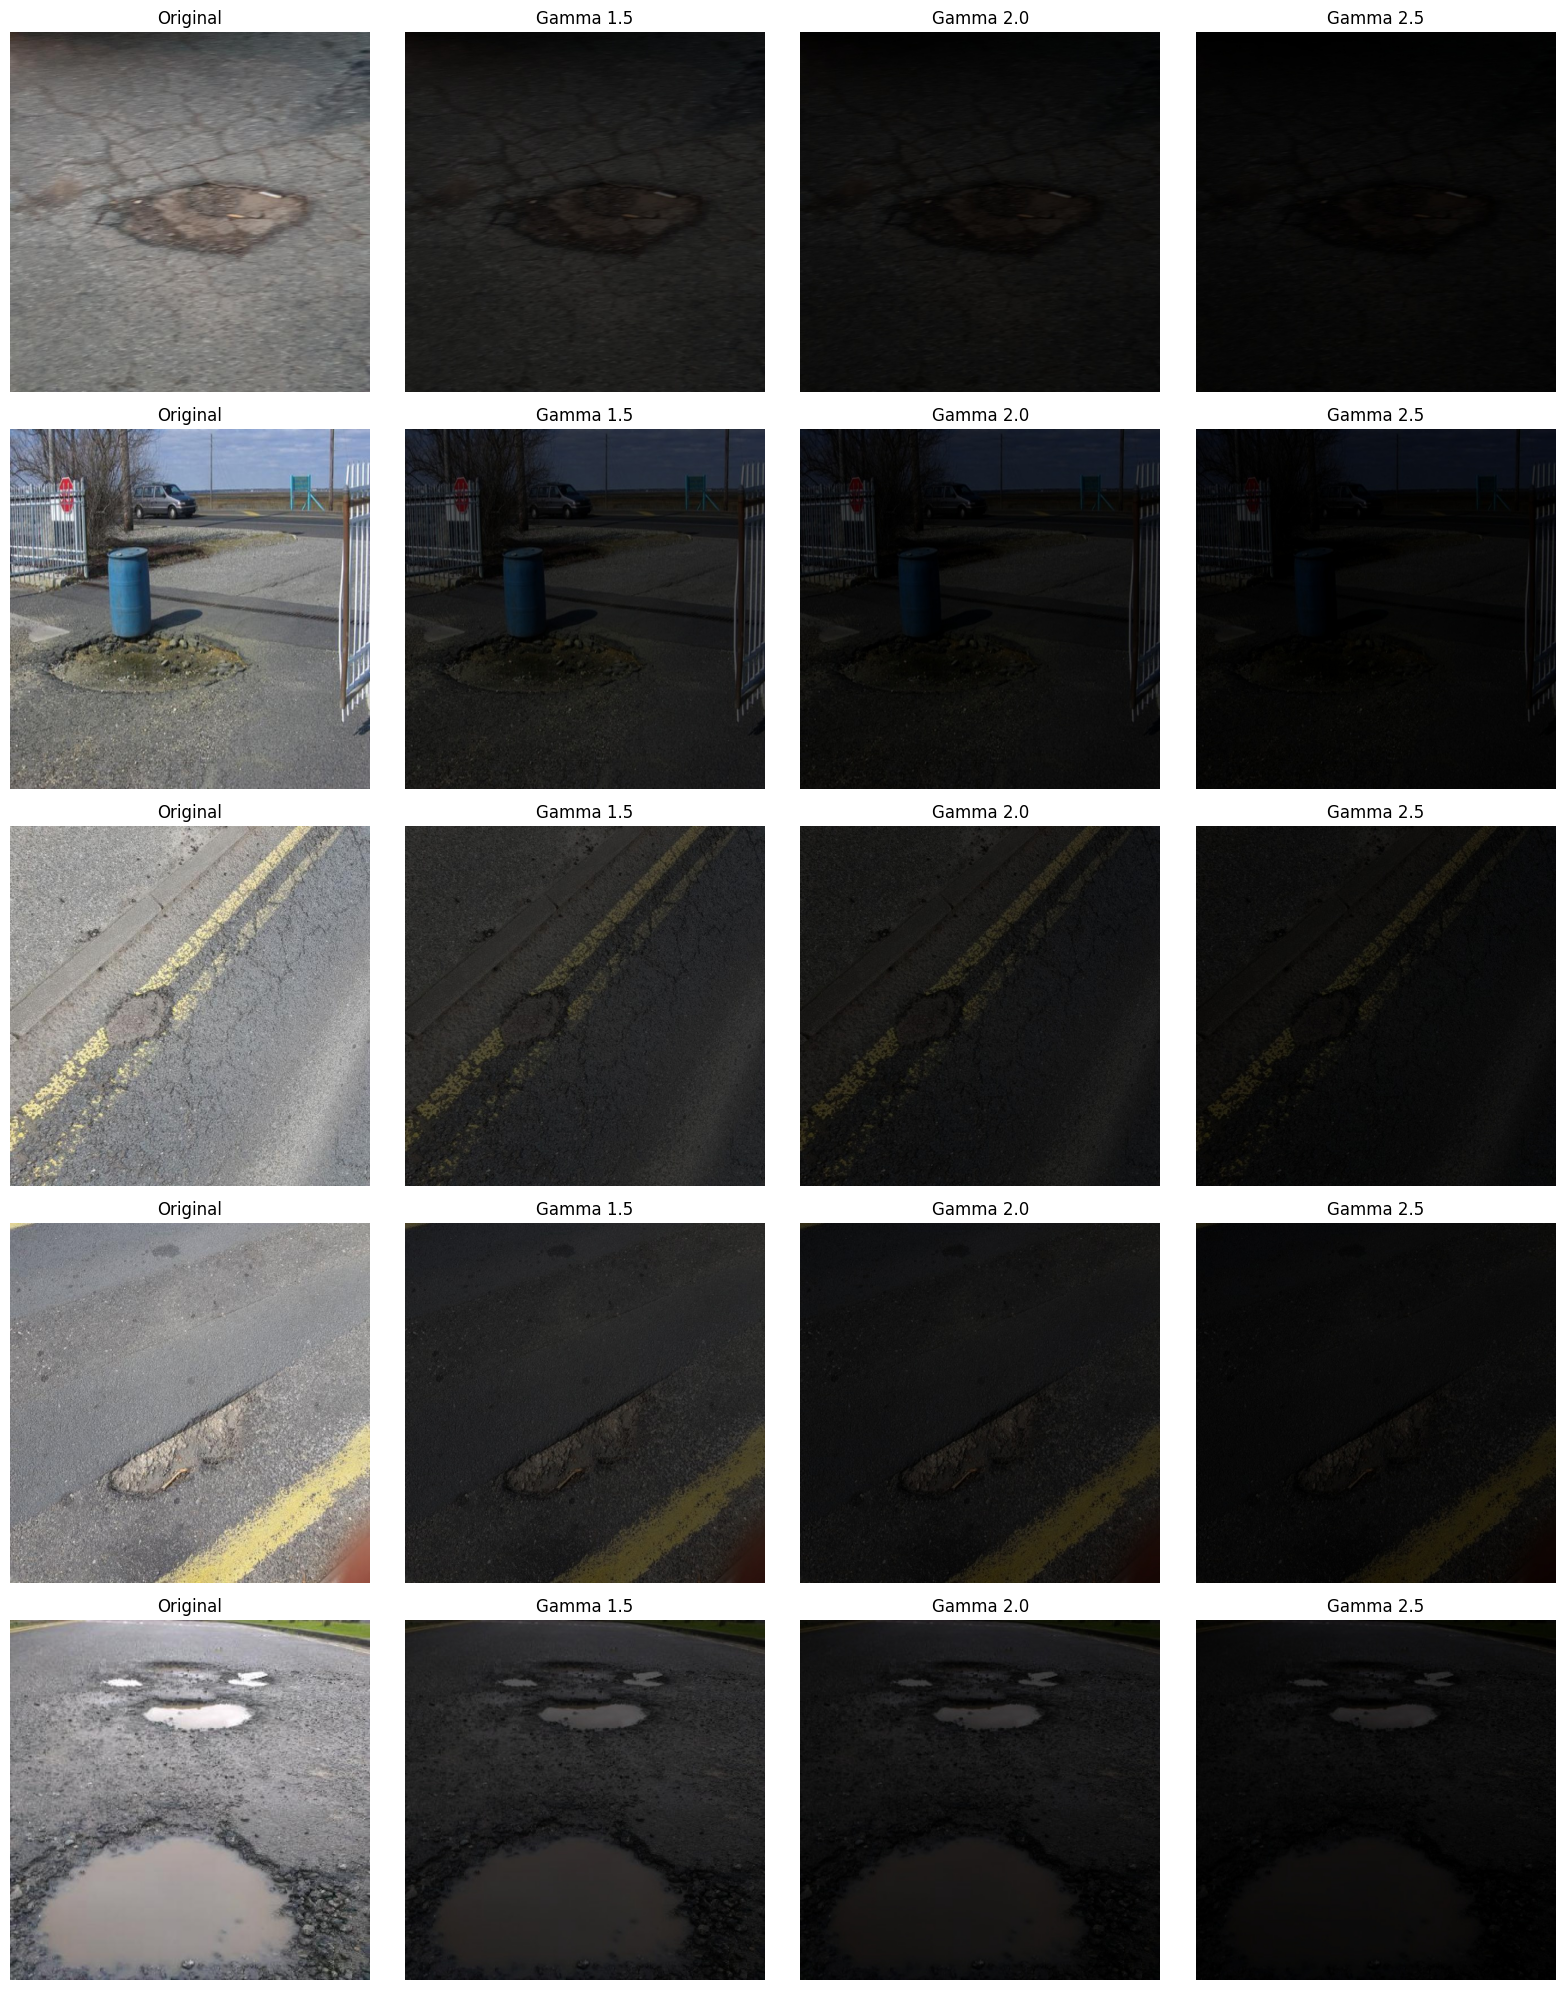

In [ ]:
import random

samples = random.sample(images, 5)

fig, axes = plt.subplots(len(samples), 4, figsize=(16, 4 * len(samples)))

for row, filename in enumerate(samples):

    original = cv2.imread(os.path.join(T1_IMAGE_DIR, filename))

    axes[row, 0].imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
    axes[row, 0].set_title("Original")
    axes[row, 0].axis("off")

    for col, gamma in enumerate(gamma_values, start=1):
        path = f"{T2_ROOT}/gamma_{gamma}/images/{filename}"
        img_dark = cv2.imread(path)

        axes[row, col].imshow(cv2.cvtColor(img_dark, cv2.COLOR_BGR2RGB))
        axes[row, col].set_title(f"Gamma {gamma}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

###สร้าง T2 / yml

In [ ]:
T1_YAML = "/content/drive/MyDrive/Image_Project/Dataset/T1/data.yaml"

with open(T1_YAML, "r") as f:
    print(f.read())

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 3
names: ['Drain Hole', 'Pothole', 'Sewer Cover']

roboflow:
  workspace: intel-unnati-training-program
  project: pothole-detection-bqu6s
  version: 9
  license: MIT
  url: https://universe.roboflow.com/intel-unnati-training-program/pothole-detection-bqu6s/dataset/9


In [ ]:
!pip install pyyaml -q

In [ ]:
import yaml

with open(T1_YAML, "r") as f:
    original_yaml = yaml.safe_load(f)

print("Class names:")
print(original_yaml["names"])

Class names:
['Drain Hole', 'Pothole', 'Sewer Cover']


In [ ]:
import os
import yaml

gamma_values = [1.5, 2.0, 2.5]

class_names = original_yaml["names"]

for gamma in gamma_values:

    dataset_root = f"{T2_ROOT}/gamma_{gamma}"

    yaml_data = {
        "path": dataset_root,
        "train": "images",
        "val": "images",
        "test": "images",
        "names": class_names
    }

    yaml_path = f"{dataset_root}/data.yaml"

    with open(yaml_path, "w") as f:
        yaml.dump(
            yaml_data,
            f,
            sort_keys=False,
            allow_unicode=True
        )

    print("Created:", yaml_path)

Created: /content/drive/MyDrive/Image_Project/Dataset/T2/gamma_1.5/data.yaml
Created: /content/drive/MyDrive/Image_Project/Dataset/T2/gamma_2.0/data.yaml
Created: /content/drive/MyDrive/Image_Project/Dataset/T2/gamma_2.5/data.yaml


In [ ]:
yaml_path = f"{T2_ROOT}/gamma_1.5/data.yaml"

with open(yaml_path, "r") as f:
    print(f.read())

path: /content/drive/MyDrive/Image_Project/Dataset/T2/gamma_1.5
train: images
val: images
test: images
names:
- Drain Hole
- Pothole
- Sewer Cover

